In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 

In [2]:
import nltk
from nltk.corpus import twitter_samples

nltk.download('twitter_samples')

all_positive_tweets = twitter_samples.strings('positive_tweets.json')
all_negative_tweets = twitter_samples.strings('negative_tweets.json')

all_positive_tweets = pd.DataFrame(all_positive_tweets)
all_positive_tweets['label'] = 1
all_negative_tweets = pd.DataFrame(all_negative_tweets)
all_negative_tweets['label'] = 0
df = pd.concat([all_positive_tweets,all_negative_tweets])

[nltk_data] Downloading package twitter_samples to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Package twitter_samples is already up-to-date!


In [3]:
df

,0,label
0,#FollowFriday @France_Inte @PKuchly57 @Milipol...,1
1,@Lamb2ja Hey James! How odd :/ Please call our...,1
2,@DespiteOfficial we had a listen last night :)...,1
3,@97sides CONGRATS :),1
4,yeaaaah yippppy!!! my accnt verified rqst has...,1
...,...,...
4995,I wanna change my avi but uSanele :(,0
4996,MY PUPPY BROKE HER FOOT :(,0
4997,where's all the jaebum baby pictures :((,0
4998,But but Mr Ahmad Maslan cooks too :( https://t...,0


In [4]:
import re
import string
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk.tokenize import TweetTokenizer

# Download the necessary NLTK resource packages if you don't have them
nltk.download('stopwords')

def process_tweet(tweet):
    """Process tweet function.
    Input:
        tweet: a string containing a tweet
    Output:
        tweets_clean: a list of words containing the processed tweet
    """
    stemmer = PorterStemmer()
    stopwords_english = stopwords.words('english')
    
    # 1. Remove old style retweet text "RT"
    tweet = re.sub(r'^RT[\s]+', '', tweet)

    # 2. Remove hyperlinks
    tweet = re.sub(r'https?:\/\/.*[\r\n]*', '', tweet)

    # 3. Remove hashtags (only removes the '#' sign, keeps the word text)
    tweet = re.sub(r'#', '', tweet)

    # 4. Remove stock market tickers like $GE
    tweet = re.sub(r'\$\w*', '', tweet)
    tweet = re.sub(r'<br />', '', tweet)

    # 5. Tokenize the tweet text
    tokenizer = TweetTokenizer(preserve_case=False, strip_handles=True, reduce_len=True)
    tweet_tokens = tokenizer.tokenize(tweet)

    tweets_clean = []
    for word in tweet_tokens:
        if (word not in stopwords_english and  # Remove stopwords
            word not in string.punctuation):   # Remove punctuation marks
            
            # Stem the word and append to clean list
            stemmed_word = stemmer.stem(word)
            tweets_clean.append(stemmed_word)

    return tweets_clean

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [5]:
import numpy as np

def build_freqs(tweets, ys):
    """Build frequencies.
    Input:
        tweets: a list of tweets
        ys: an m x 1 array with the sentiment label of each tweet
            (either 0 or 1)
    Output:
        freqs: a dictionary mapping each (word, sentiment) pair to its
               frequency
    """
    # Convert np array to list since zip needs an iterable
    # squeeze removes single-dimensional entries from the shape of an array
    yslist = np.squeeze(ys).tolist()

    # Start with an empty dictionary
    freqs = {}
    
    # Iterate through all tweets and labels
    for y, tweet in zip(yslist, tweets):
        # Process the tweet to get a list of clean, stemmed words
        for word in process_tweet(tweet):
            # Define the key as a tuple: (word, label)
            pair = (word, y)
            
            # Update the count in the dictionary
            if pair in freqs:
                freqs[pair] += 1
            else:
                freqs[pair] = 1
                
    return freqs


In [6]:
freqs = build_freqs(df[0],df['label'])

In [ ]:
freqs

In [14]:
import pickle
with open('data.pkl', 'wb') as file:
    pickle.dump(freqs, file)

In [110]:
df['processed_tweet'] = df[0].apply(process_tweet)

In [111]:
def freq_func(review):
    pos = 0
    neg = 0
    for word in review:
        pos = pos + freqs.get((word,1),0)
        neg = neg + freqs.get((word,0),0)
    return pos, neg

In [113]:
df['pos'] = df['processed_tweet'].apply(freq_func).apply(lambda x:x[0])

In [114]:
df['neg'] = df['processed_tweet'].apply(freq_func).apply(lambda x:x[1])

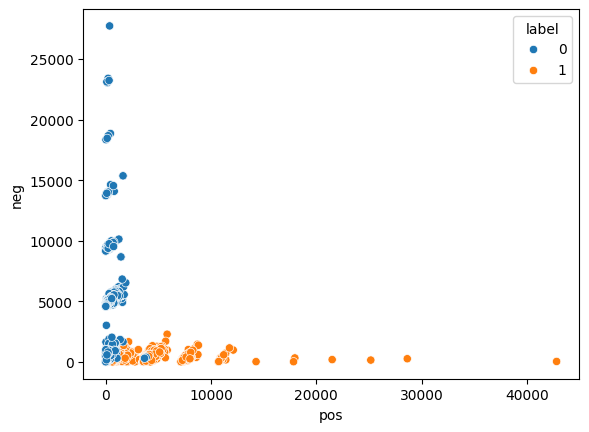

In [115]:
import seaborn as sns
sns.scatterplot(data=df,x= 'pos',y= 'neg',hue='label')
plt.show()

In [116]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(df[['pos','neg']],df['label'],random_state=42,test_size=0.33)

In [117]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
x_train_scaled = sc.fit_transform(X_train)
x_test_scaled = sc.transform(X_test)

In [118]:
from sklearn.linear_model import LogisticRegression
LR = LogisticRegression()
LR.fit(x_train_scaled,y_train)
y_pred = LR.predict(x_test_scaled)

In [119]:
from sklearn.metrics import accuracy_score
accuracy_score(y_pred,y_test)

0.9903030303030304

In [120]:
import joblib
joblib.dump(LR,"model.pkl")

['model.pkl']